In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
BRIDGE = "data/bridge_matrices.xlsx"
IMPACTS = "data/bubble_data_by_indicator_2015.xlsx"
FOOTPRINT = "M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp"
ID_COLS = ["Food","category", "sub_category", "sector"]
AGGREGATION = ["M_analyse","M_regimes_alimentaires","M_base_vg_animal"] #"M_base_agri_land","M_base_eau bleue"]
LIMITS = ["N surplus","Blue water consumption","GHG emissions","Agricultural land","Biodiversity loss - HANPP"]
SUFFIX = ["_N","_blue_water","_CO2eq","_agri_land","_HANPP"]


Fonction d'import des agrégats des secteurs

In [3]:
def load_aggregated_sectors(sheet, path=BRIDGE):
    """Rôle :  Récupérer les noms des secteurs agrégés qui serviront de base de départ pour les databases (.pkl)
       Input : un nom de feuille excel ; en option, le nom du fichier excel, ici par defaut le fichier qu'on utilisera
       Output : un dataframe panda avec pour index les secteurs aggrégés"""
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    attributes = [str(v).strip() for v in raw.iloc[0, 4:]]     # Food, Cereals, ... (ligne 0)
    df = raw.iloc[2:].reset_index(drop=True)              # ligne 1 = en-têtes category/sub_category/sector
    df.columns = ID_COLS + attributes
    for c in ID_COLS:
        df[c] = df[c].astype(str).str.strip()
    df[attributes] = df[attributes].apply(pd.to_numeric).fillna(0).astype(int)  # 0/1 : appartenance à l'attribut
    df = df.set_index(ID_COLS[-1])
    return df

Fonction d'import des impacts par secteur

In [4]:
def load_impacts(sheet_limit, path=IMPACTS):
    """Rôle : Transformer une des feuille d'impacts pour une des limites planétaires, fourni par Arnaud en un dataframe panda
       Input : le nom de la feuille contenant la limite planétaire concernée
       Output : un dataframe python contenant toutes les valeurs données en Source data"""
    raw = pd.read_excel(path, sheet_name=sheet_limit, header=None)
    start = raw.index[raw[0].astype(str).str.startswith("Source data")][0] + 1
    block = raw.iloc[start:].set_index(0)
    block.columns = [str(c).strip() for c in block.iloc[0]]
    block = block.iloc[1:]
    
    block = block.apply(pd.to_numeric, errors="coerce")
    block = block.dropna(how="all")
    
    block.index.name = sheet_limit
    return block

Import de l'ensemble des données d'impact dans une database .pkl

In [20]:
db_impacts=load_aggregated_sectors(AGGREGATION[0])[[]] #initialisation avec un index des secteurs, sous forme de DataFrame Panda
db_impacts=db_impacts.join(load_impacts(LIMITS[0]).loc[["Y_imp","Y_dom"]].T) #ajout des Y, valeurs communes à l'ensemble des feuilles de limites planétaires

#ajout des valeurs pour chaque limite planétaire concernée (listées dans LIMITS), en utilisant la fonction précédente
for i in range(len(LIMITS)):
    limit, suffix = LIMITS[i], SUFFIX[i]
    impact = load_impacts(limit)
    db_impacts=db_impacts.join(impact.loc[["M_imp","M_dom","M_row","M_imp*Y_dom","M_dom*Y_dom","M_imp*Y_dom+M_dom*Y_dom","M_row*Y_imp","M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp"]].T.add_suffix(suffix))
db_impacts.to_pickle("pkl/impacts.pkl") #conversion en .pkl

In [21]:
pd.read_pickle("pkl/impacts.pkl")

,Y_imp,Y_dom,M_imp_N,M_dom_N,M_row_N,M_imp*Y_dom_N,M_dom*Y_dom_N,M_imp*Y_dom+M_dom*Y_dom_N,M_row*Y_imp_N,M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp_N,...,M_row*Y_imp_agri_land,M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp_agri_land,M_imp_HANPP,M_dom_HANPP,M_row_HANPP,M_imp*Y_dom_HANPP,M_dom*Y_dom_HANPP,M_imp*Y_dom+M_dom*Y_dom_HANPP,M_row*Y_imp_HANPP,M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp_HANPP
sector,,,,,,,,,,,,,,,,,,,,,
Paddy rice,12.589531,111.123786,1.989383e-07,7.090982e-06,2.363631e-05,0.000022,0.000788,0.000810,0.000298,0.001108,...,80.538861,236.644738,3.898873e-08,3.625879e-07,3.116650e-06,0.000004,0.000040,0.000045,0.000039,0.000084
Wheat,393.416838,6143.007796,9.804582e-08,8.873836e-06,2.296390e-05,0.000602,0.054512,0.055114,0.009034,0.064149,...,1882.540194,13954.108521,1.696099e-08,4.470634e-07,2.178718e-06,0.000104,0.002746,0.002851,0.000857,0.003708
Cereal grains nec,6.170734,370.683466,6.442566e-08,7.347113e-06,1.735082e-05,0.000024,0.002723,0.002747,0.000107,0.002854,...,25.551542,456.100979,1.132720e-08,4.007369e-07,2.189237e-06,0.000004,0.000149,0.000153,0.000014,0.000166
"Vegetables, fruit, nuts",6666.413096,10280.107605,3.666241e-07,2.252354e-06,1.050347e-05,0.003769,0.023154,0.026923,0.070020,0.096944,...,21190.518515,31959.552765,4.772722e-08,2.315433e-07,9.025651e-07,0.000491,0.002380,0.002871,0.006017,0.008888
Oil seeds,709.186797,726.078487,1.513198e-07,4.118261e-05,1.680156e-05,0.000110,0.029902,0.030012,0.011915,0.041927,...,5459.374499,8178.458721,2.583717e-08,8.226656e-07,1.840119e-06,0.000019,0.000597,0.000616,0.001305,0.001921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Membership organisation services n.e.c. (91),95.863337,22590.510068,2.204345e-07,5.997452e-08,1.790537e-06,0.004980,0.001355,0.006335,0.000172,0.006506,...,56.269096,2230.352802,2.872476e-08,5.034518e-09,1.634473e-07,0.000649,0.000114,0.000763,0.000016,0.000778
"Recreational, cultural and sporting services (92)",2481.468221,71885.084968,2.302573e-07,2.088215e-07,4.540206e-07,0.016552,0.015011,0.031563,0.001127,0.032690,...,411.411210,8315.588728,2.920231e-08,1.725449e-08,4.622357e-08,0.002099,0.001240,0.003340,0.000115,0.003454
Other services (93),262.192337,11238.476071,3.409486e-07,1.059440e-08,6.139356e-07,0.003832,0.000119,0.003951,0.000161,0.004112,...,72.156337,1643.982154,4.495945e-08,9.099804e-10,7.766778e-08,0.000505,0.000010,0.000516,0.000020,0.000536


Import des tableaux d'aggrégation en python

In [22]:
#pour chaque tableau d'aggrégation, on créé un pkl avec le calcul des valeurs
for aggregate in AGGREGATION:
    impacts = pd.read_pickle("pkl/impacts.pkl")
    d = load_aggregated_sectors(aggregate).merge(impacts,left_on="sector", right_index=True, how="left")
    d.to_pickle("pkl/"+aggregate+".pkl")

In [23]:
#exemple
pd.read_pickle("./pkl/M_analyse.pkl")

,Food,category,sub_category,Cereals,"Vegetables, fruits, nuts",Oil & Fats,Agri-food nec,Meat cattle,Dairy Products,Animal products nec,...,M_row*Y_imp_agri_land,M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp_agri_land,M_imp_HANPP,M_dom_HANPP,M_row_HANPP,M_imp*Y_dom_HANPP,M_dom*Y_dom_HANPP,M_imp*Y_dom+M_dom*Y_dom_HANPP,M_row*Y_imp_HANPP,M_imp*Y_dom+M_dom*Y_dom+M_row*Y_imp_HANPP
sector,,,,,,,,,,,,,,,,,,,,,
Paddy rice,Food,Agriculture,Primary_Crops,1,0,0,0,0,0,0,...,80.538861,236.644738,3.898873e-08,3.625879e-07,3.116650e-06,0.000004,0.000040,0.000045,0.000039,0.000084
Wheat,Food,Agriculture,Primary_Crops,1,0,0,0,0,0,0,...,1882.540194,13954.108521,1.696099e-08,4.470634e-07,2.178718e-06,0.000104,0.002746,0.002851,0.000857,0.003708
Cereal grains nec,Food,Agriculture,Primary_Crops,1,0,0,0,0,0,0,...,25.551542,456.100979,1.132720e-08,4.007369e-07,2.189237e-06,0.000004,0.000149,0.000153,0.000014,0.000166
"Vegetables, fruit, nuts",Food,Agriculture,Primary_Crops,0,1,0,0,0,0,0,...,21190.518515,31959.552765,4.772722e-08,2.315433e-07,9.025651e-07,0.000491,0.002380,0.002871,0.006017,0.008888
Oil seeds,Food,Agriculture,Primary_Crops,0,0,1,0,0,0,0,...,5459.374499,8178.458721,2.583717e-08,8.226656e-07,1.840119e-06,0.000019,0.000597,0.000616,0.001305,0.001921
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Membership organisation services n.e.c. (91),NaN,Oth_services,Business_services,0,0,0,0,0,0,0,...,56.269096,2230.352802,2.872476e-08,5.034518e-09,1.634473e-07,0.000649,0.000114,0.000763,0.000016,0.000778
"Recreational, cultural and sporting services (92)",NaN,Oth_services,Business_services,0,0,0,0,0,0,0,...,411.411210,8315.588728,2.920231e-08,1.725449e-08,4.622357e-08,0.002099,0.001240,0.003340,0.000115,0.003454
Other services (93),NaN,Oth_services,Business_services,0,0,0,0,0,0,0,...,72.156337,1643.982154,4.495945e-08,9.099804e-10,7.766778e-08,0.000505,0.000010,0.000516,0.000020,0.000536


In [ ]:
#graphiques à développer

#graph = analyse.query(" ").groupby("category")["impact"].sum().sort_values().plot.barh(figsize=(8, 5))
#plt.xlabel(FOOTPRINT); plt.title("Biodiversity loss - HANPP par catégorie"); plt.tight_layout(); plt.show()

In [ ]:
def sector_to_aggregation(analyse):
    """Rôle : Transformer les données d'impacts par secteurs en données par aggrégation
           Input : feuille contenant les impacts + la matrice des correspondances secteurs-aggrégations
           Output : un dataframe python contenant les empreintes par aggrégation et par limite"""
    cols = list(analyse.columns)
    start = cols.index("sub_category") + 1
    end = next(i for i, c in enumerate(cols) if str(c).startswith("Y"))
    cats = cols[start:end]

    #tri des lignes concernant uniquement le domaine des "Food"
    mask = analyse["Food"].notna()
    sub = analyse.loc[mask]
    D = analyse.loc[mask, cats].fillna(0).astype(float)

    footprint = D.T[[]]
    for i in range(len(SUFFIX)):
        footprint["total"+SUFFIX[i]]=D.T @ sub[FOOTPRINT+SUFFIX[i]].fillna(0)
        
    return footprint # ici il n'y a que footprint pour l'instant, mais on peut rajouter l'intensité moyenne ou l'intensité par calorie...


In [57]:
# test sur les aggrégations initiales
analyse = pd.read_pickle("./pkl/M_analyse.pkl")
footprint = sector_to_aggregation(analyse)

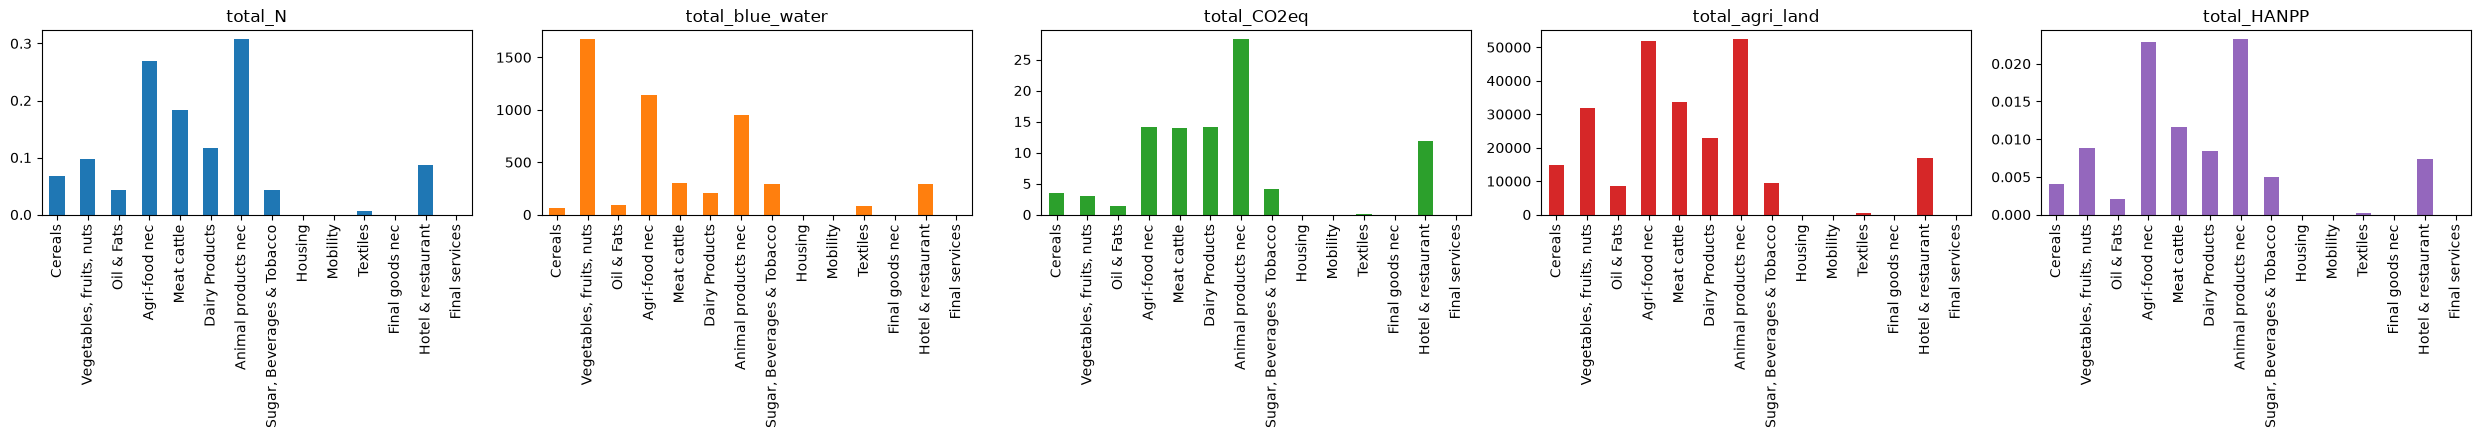

In [ ]:
# affichage des résultats
nrows, ncols = footprint.shape
footprint.plot.bar(subplots=True, layout=(nrows, ncols), figsize=(5 * ncols, 4 * nrows), legend=False)
plt.tight_layout()
plt.show()